##### note that all data analysis checks for recreated servicewide analyses are found in the servicewide analysis jupyter notebook 

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import AutoMinorLocator
import matplotlib.patches as mpatches
import docx

C:\Users\Sophie.Kaye\Anaconda3\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.4)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


In [2]:
myworkingdirectory = r"C:\Users\Sophie.Kaye\Desktop\NPS Crash Data"
os.chdir(myworkingdirectory)

In [3]:
analysis_2024 = pd.read_csv("./analysis_database_2024.csv")

<ipython-input-3-60bb7cbbd6e1>:1: DtypeWarning: Columns (68) have mixed types. Specify dtype option on import or set low_memory=False.
  analysis_2024 = pd.read_csv("./analysis_database_2024.csv")


In [4]:
analysis_2024.shape

(218593, 71)

In [5]:
analysis_2024.head()

,INCID_NO,5_mph,10_mph,15_mph,20_mph,25_mph,30_mph,35_mph,40_mph,45_mph,...,LONGITUDE,Park,RGN,YEAR,MONTH,DOW,HOUR,TIME,Urban,database
0,ABLI070425075000,0,0,0,0,0,0,0,0,0,...,NaN,ABLI,SER,2007.0,4,3,7,750.0,rural,CDS
1,ABLI070804175500,1,0,0,0,0,0,0,0,0,...,NaN,ABLI,SER,2007.0,8,6,17,1755.0,rural,CDS
2,ABLI091117170900,0,0,0,0,1,0,0,0,0,...,NaN,ABLI,SER,2009.0,11,2,17,1709.0,rural,CDS
3,ABLI121009110000,0,0,0,0,1,0,0,0,0,...,NaN,ABLI,SER,2012.0,10,2,11,1100.0,rural,CDS
4,ABLI140610163500,0,0,0,0,0,0,0,0,0,...,-76.93412,ABLI,SER,2014.0,6,2,16,1635.0,rural,CDS


In [6]:
analysis_2024.columns

Index(['INCID_NO', '5_mph', '10_mph', '15_mph', '20_mph', '25_mph', '30_mph',
       '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph', '65_mph',
       '70_mph', '75_mph', 'no_posted_speed', 'Crosswalk',
       'Outside a Crosswalk', 'NUM_VEH', 'Num_Motorcycle', 'Pax', 'SUV', 'Van',
       'Bus', 'Medium Truck', 'Heavy Truck', 'Equipment', 'Nonroad HighSpeed',
       'Nonroad LowSpeed', 'Unknown', 'Motorcycle_Ind', 'No Injury',
       'Possible Injury', 'Non-incapacitating Injury', 'Incapacitating Injury',
       'Fatality', 'Num_Motorist', 'Num_Non_Motorist', 'Num_Pedestrian',
       'Num_Ped_Deaths', 'Pedestrian', 'VRU', 'Crash_Severity',
       'CrashSeverity_Fatal', 'CrashSeverity_Incap', 'CrashSeverity_NonIncap',
       'CrashSeverity_Possible', 'CrashSeverity_NoInj', 'First_Harmful_Event',
       'First_Harmful_Event_Type', 'Involving Animal', 'Daylight', 'Dawn',
       'Dusk', 'Dark_Lit', 'Dark_NotLit', 'Dark_UnknownLit',
       'UnknownBlankNullLit', 'Poor Lighting', 

# 2D Heatmap Plotting

## Percent of Total Fatalities

In [8]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    allfatals = df[['HOUR','MONTH','Fatality']]
    allfatals_agg = allfatals.groupby(['MONTH','HOUR']).sum().reset_index() # aggregate all fatalities at same month and hour

    totalfatals = df['Fatality'].sum()
    allfatals_perc = allfatals_agg[['HOUR','MONTH']] # set up percent table
    allfatals_perc['Fatality'] = allfatals_agg['Fatality']/totalfatals*100 # compute percent value
    allfatals_perc.to_csv('./allfatals_perc_' + region + '.csv', index = False) # print values for manual fix if needed for missing values

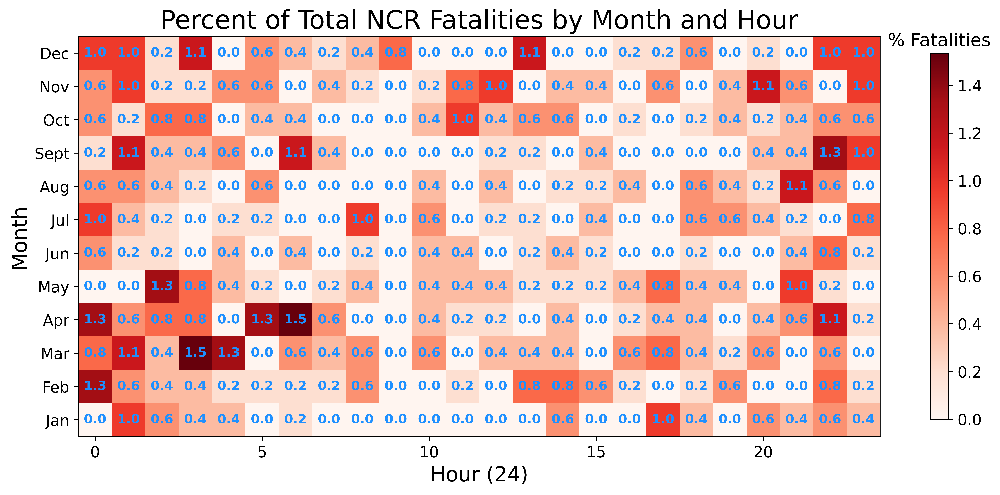

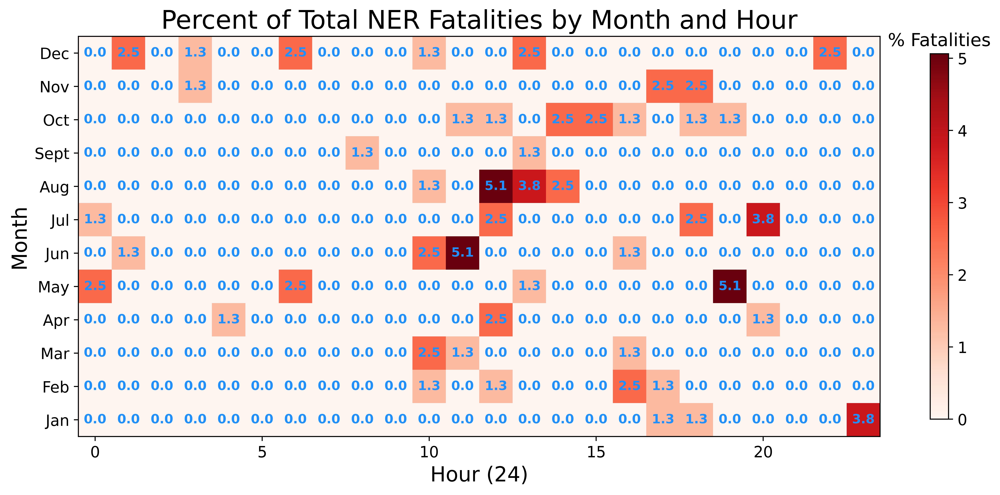

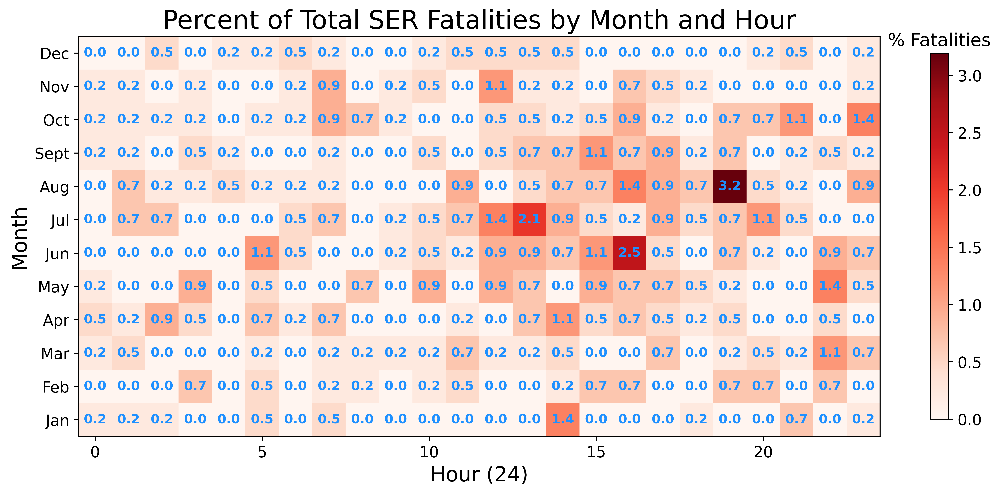

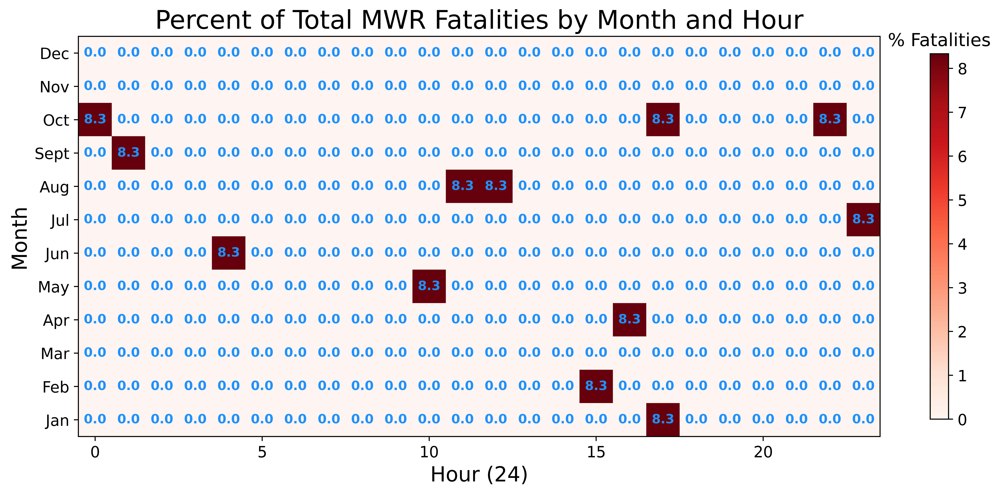

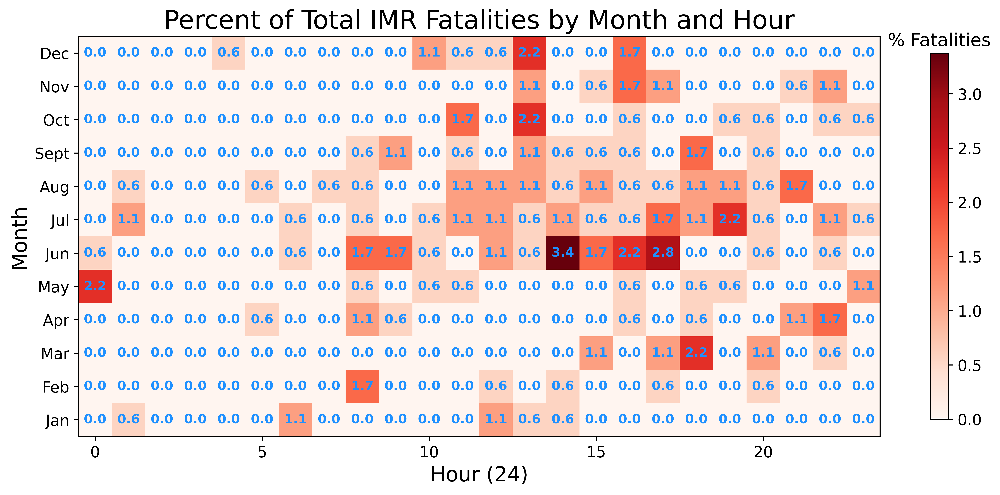

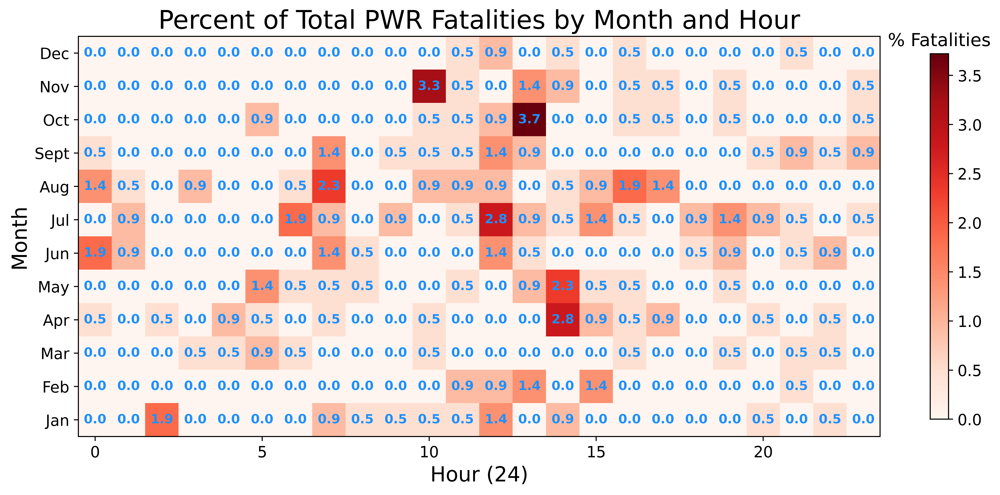

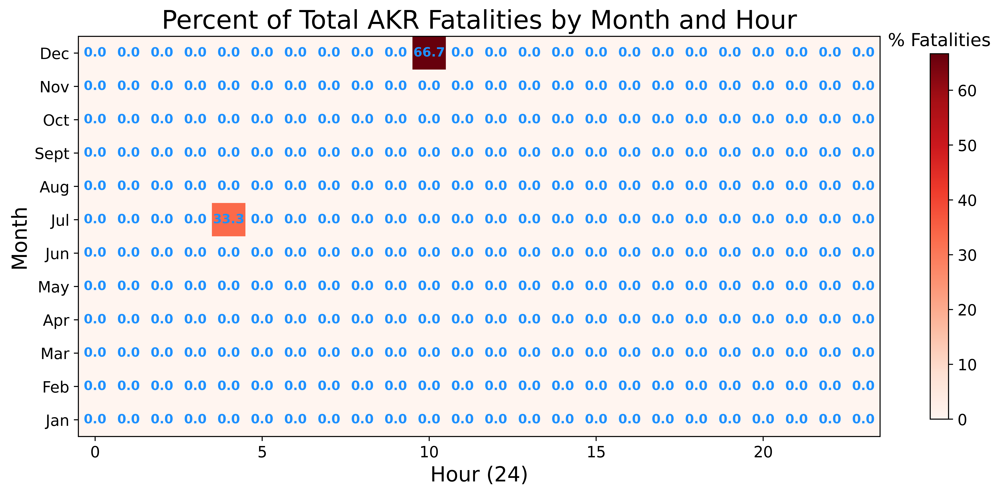

In [10]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    allfatals_perc = pd.read_csv("./manually fixed data/allfatals_perc_" + region + ".csv") # read in manually fixed files for further processing
    # pull out columns for each hour
    midnight_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==0.0]
    one_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==1.0]
    two_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==2.0]
    three_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==3.0]
    four_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==4.0]
    five_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==5.0]
    six_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==6.0]
    seven_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==7.0]
    eight_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==8.0]
    nine_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==9.0]
    ten_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==10.0]
    eleven_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==11.0]
    twelve_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==12.0]
    thirteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==13.0]
    fourteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==14.0]
    fifteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==15.0]
    sixteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==16.0]
    seventeen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==17.0]
    eighteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==18.0]
    nineteen_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==19.0]
    twenty_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==20.0]
    twentyone_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==21.0]
    twentytwo_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==22.0]
    twentythree_allfatals_perc = allfatals_perc['Fatality'].loc[allfatals_perc['HOUR']==23.0]

    # combine columns into wide array
    allfatals_perc_array = pd.DataFrame(np.column_stack([midnight_allfatals_perc,one_allfatals_perc,two_allfatals_perc,three_allfatals_perc,four_allfatals_perc,five_allfatals_perc,six_allfatals_perc,seven_allfatals_perc,eight_allfatals_perc,nine_allfatals_perc,ten_allfatals_perc,eleven_allfatals_perc,twelve_allfatals_perc,thirteen_allfatals_perc,fourteen_allfatals_perc,fifteen_allfatals_perc,sixteen_allfatals_perc,seventeen_allfatals_perc,eighteen_allfatals_perc,nineteen_allfatals_perc,twenty_allfatals_perc,twentyone_allfatals_perc,twentytwo_allfatals_perc,twentythree_allfatals_perc]), columns=['midnight_allfatals_perc','one_allfatals_perc','two_allfatals_perc','three_allfatals_perc','four_allfatals_perc','five_allfatals_perc','six_allfatals_perc','seven_allfatals_perc','eight_allfatals_perc','nine_allfatals_perc','ten_allfatals_perc','eleven_allfatals_perc','twelve_allfatals_perc','thirteen_allfatals_perc','fourteen_allfatals_perc','fifteen_allfatals_perc','sixteen_allfatals_perc','seventeen_allfatals_perc','eighteen_allfatals_perc','nineteen_allfatals_perc','twenty_allfatals_perc','twentyone_allfatals_perc','twentytwo_allfatals_perc','twentythree_allfatals_perc'])
    allfatals_perc_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec'] # prep to set array index
    allfatals_perc_array = allfatals_perc_array.set_index('month') # set array index
    allfatals_perc_array_reorder = np.flipud(allfatals_perc_array) # reverse row index so months match order in FHWA EDC-7 plots

    # generate figure
    fig, ax = plt.subplots(figsize=(14,7), dpi=700)
    im = ax.imshow(allfatals_perc_array_reorder, cmap = "Reds")
    months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
    plt.yticks(range(len(months)), months, fontsize = 12)
    plt.xticks(fontsize = 12)
    cbar = ax.figure.colorbar(im, shrink = 0.75)
    cbar.ax.set_title('% Fatalities', fontsize = 14)
    cbar.ax.tick_params(labelsize=12)
    ax.set_xlabel("Hour (24)", fontsize = 16)
    ax.set_ylabel("Month", fontsize = 16)
    ax.set_title("Percent of Total " + region + " Fatalities by Month and Hour", size = 20)

    for i in range(len(months)):
        for j in range(24):
            text = ax.text(j, i, round(allfatals_perc_array_reorder[i, j],1), ha="center", va="center", color="dodgerblue", weight="bold")

#    fig_name = './Figures/2D heatmaps/Percent Total Fatalities/' + region + ".png"
#    plt.savefig(fig_name)

## Percent of Crashes Involving Animals

In [11]:
for region in regions:
    animal = analysis_2024.loc[analysis_2024['Involving Animal']==1.0]
    df = animal.loc[animal['RGN']==region]
    animalcount = df[['HOUR','MONTH']]
    animalcount['Count'] = 1
    animalcount_agg = animalcount.groupby(['MONTH','HOUR']).sum().reset_index() # aggregate all crashes at same month and hour

    animaltotal = animalcount['Count'].sum()
    animalcount_perc = animalcount_agg[['HOUR','MONTH']] # set up percent table
    animalcount_perc['Count'] = animalcount_agg['Count']/animaltotal*100 # compute percent value
    animalcount_perc.to_csv('./animalcount_perc_' + region + '.csv', index = False) # print values for manual fix if needed for missing values

<ipython-input-11-40a0762e53ca>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  animalcount['Count'] = 1
<ipython-input-11-40a0762e53ca>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  animalcount['Count'] = 1
<ipython-input-11-40a0762e53ca>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returnin

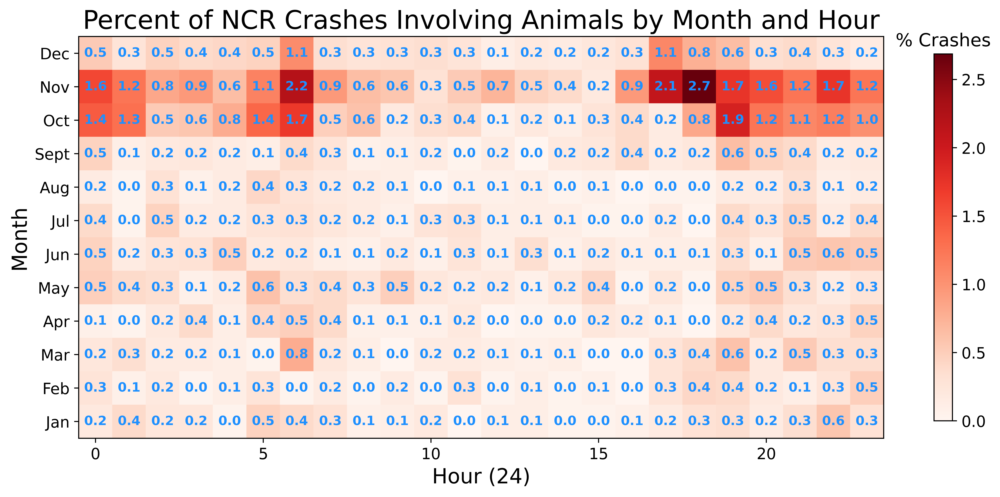

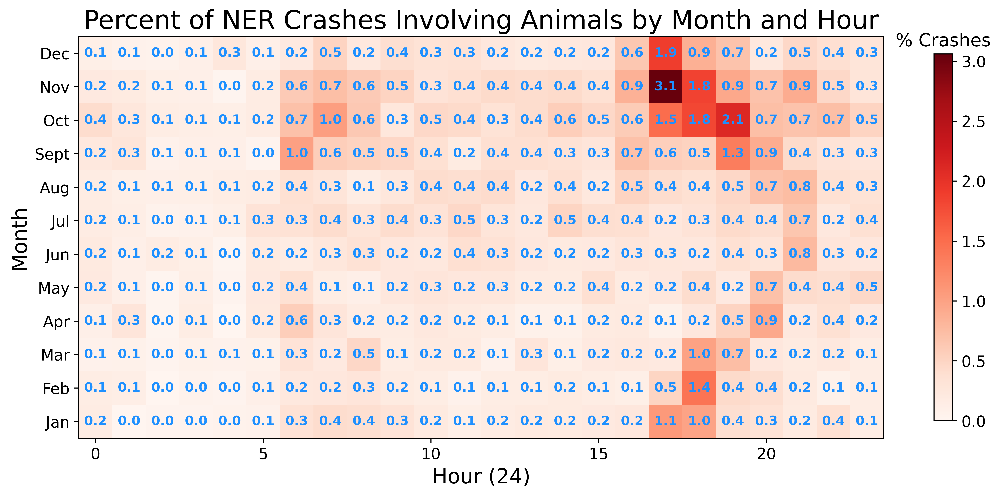

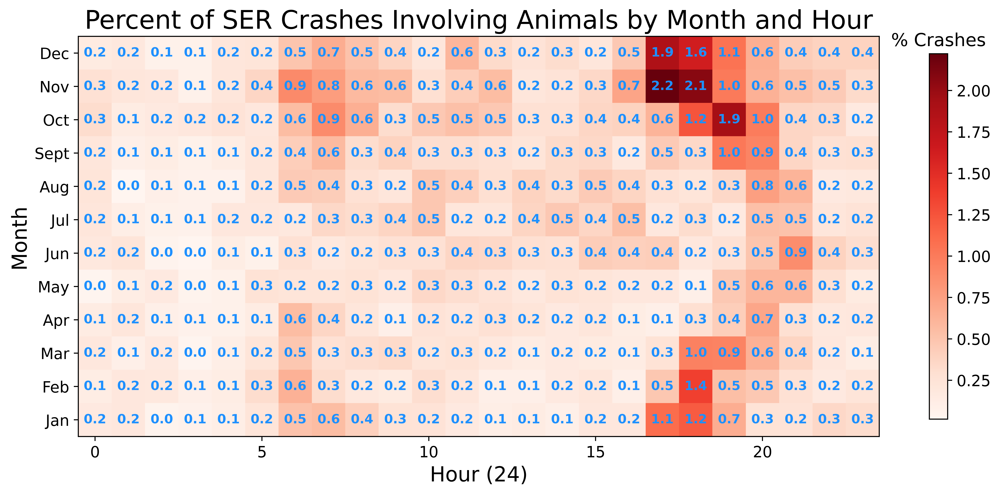

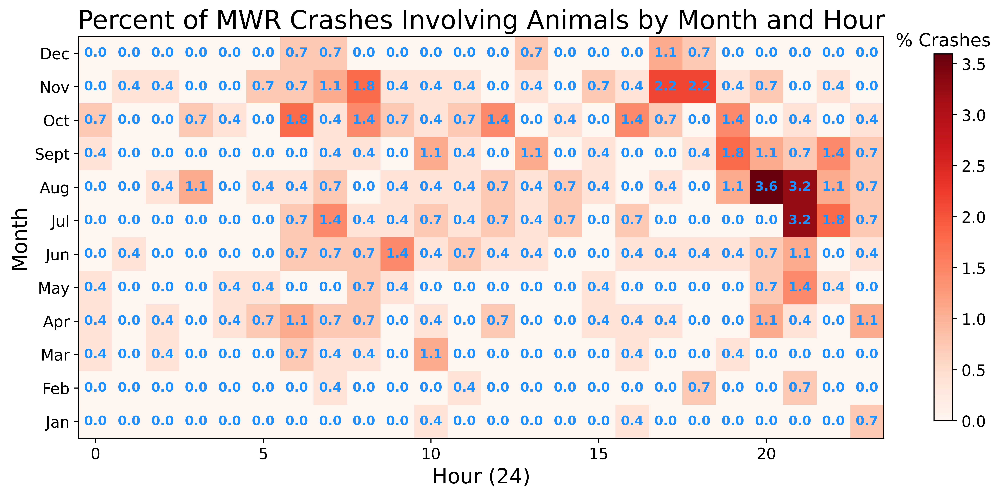

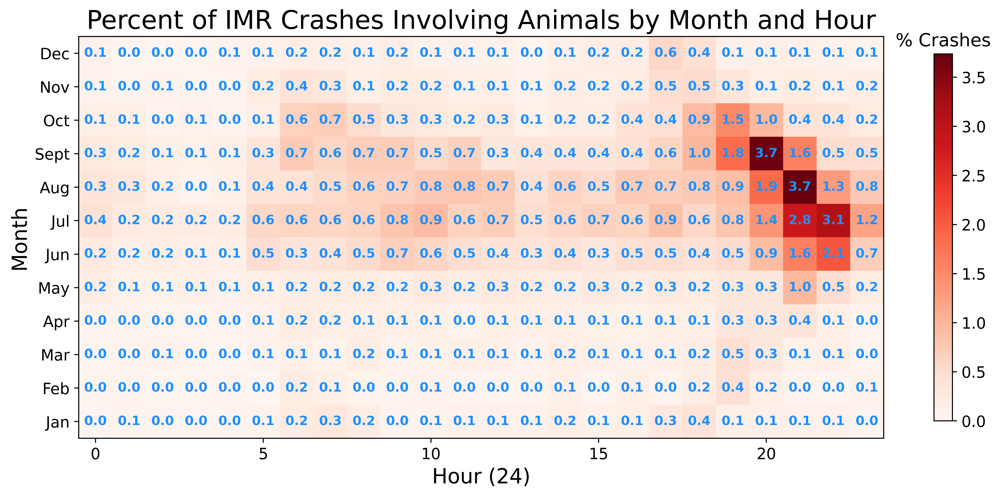

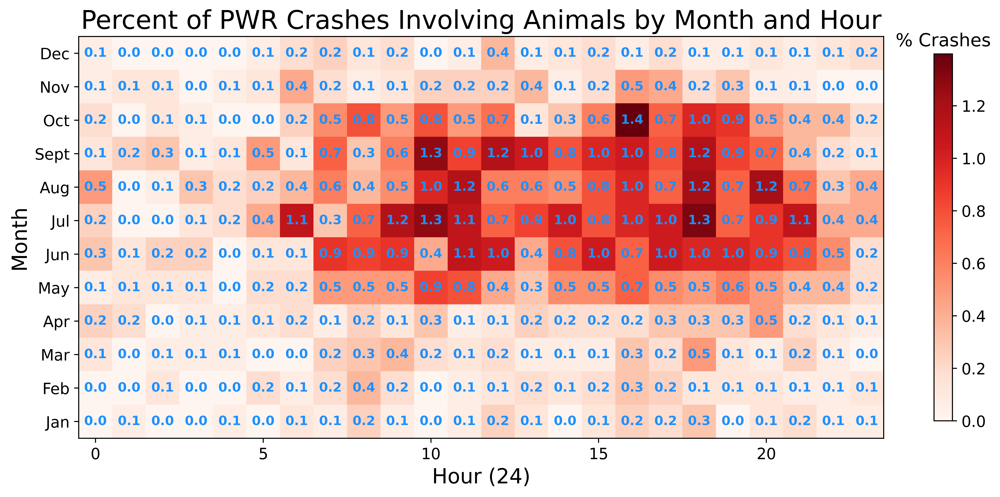

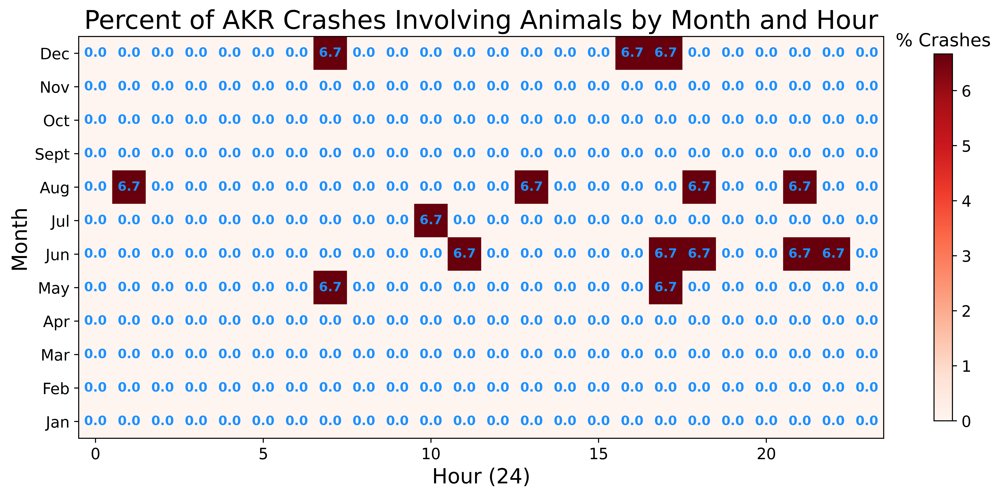

In [17]:
for region in regions:
    animalcount_perc = pd.read_csv("./manually fixed data/animalcount_perc_" + region + ".csv") # read in manually fixed files for further processing
    # pull out columns for each hour
    midnight_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==0.0]
    one_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==1.0]
    two_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==2.0]
    three_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==3.0]
    four_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==4.0]
    five_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==5.0]
    six_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==6.0]
    seven_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==7.0]
    eight_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==8.0]
    nine_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==9.0]
    ten_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==10.0]
    eleven_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==11.0]
    twelve_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==12.0]
    thirteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==13.0]
    fourteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==14.0]
    fifteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==15.0]
    sixteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==16.0]
    seventeen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==17.0]
    eighteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==18.0]
    nineteen_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==19.0]
    twenty_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==20.0]
    twentyone_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==21.0]
    twentytwo_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==22.0]
    twentythree_animalcount_perc = animalcount_perc['Count'].loc[animalcount_perc['HOUR']==23.0]

    # combine columns into wide array
    animalcount_perc_array = pd.DataFrame(np.column_stack([midnight_animalcount_perc,one_animalcount_perc,two_animalcount_perc,three_animalcount_perc,four_animalcount_perc,five_animalcount_perc,six_animalcount_perc,seven_animalcount_perc,eight_animalcount_perc,nine_animalcount_perc,ten_animalcount_perc,eleven_animalcount_perc,twelve_animalcount_perc,thirteen_animalcount_perc,fourteen_animalcount_perc,fifteen_animalcount_perc,sixteen_animalcount_perc,seventeen_animalcount_perc,eighteen_animalcount_perc,nineteen_animalcount_perc,twenty_animalcount_perc,twentyone_animalcount_perc,twentytwo_animalcount_perc,twentythree_animalcount_perc]), columns=['midnight_animalcount_perc','one_animalcount_perc','two_animalcount_perc','three_animalcount_perc','four_animalcount_perc','five_animalcount_perc','six_animalcount_perc','seven_animalcount_perc','eight_animalcount_perc','nine_animalcount_perc','ten_animalcount_perc','eleven_animalcount_perc','twelve_animalcount_perc','thirteen_animalcount_perc','fourteen_animalcount_perc','fifteen_animalcount_perc','sixteen_animalcount_perc','seventeen_animalcount_perc','eighteen_animalcount_perc','nineteen_animalcount_perc','twenty_animalcount_perc','twentyone_animalcount_perc','twentytwo_animalcount_perc','twentythree_animalcount_perc'])
    animalcount_perc_array['month']=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sept','Oct','Nov','Dec'] # prep to set array index
    animalcount_perc_array = animalcount_perc_array.set_index('month') # set array index
    animalcount_perc_array_reorder = np.flipud(animalcount_perc_array) # reverse row index so months match order in FHWA EDC-7 plots

    # generate figure
    fig, ax = plt.subplots(figsize=(14,7), dpi=700)
    im = ax.imshow(animalcount_perc_array_reorder, cmap = "Reds")
    months = ['Dec','Nov','Oct','Sept','Aug','Jul','Jun','May','Apr','Mar','Feb','Jan']
    plt.yticks(range(len(months)), months, fontsize = 12)
    plt.xticks(fontsize = 12)
    cbar = ax.figure.colorbar(im, shrink = 0.75)
    cbar.ax.set_title('% Crashes', fontsize = 14)
    cbar.ax.tick_params(labelsize=12)
    ax.set_xlabel("Hour (24)", fontsize = 16)
    ax.set_ylabel("Month", fontsize = 16)
    ax.set_title("Percent of " + region + " Crashes Involving Animals by Month and Hour", size = 20)

    for i in range(len(months)):
        for j in range(24):
            text = ax.text(j, i, round(animalcount_perc_array_reorder[i, j],1), ha="center", va="center", color="dodgerblue", weight="bold")

    #fig_name = './Figures/2D heatmaps/Percent Animal Crashes/' + region + ".png"
    #plt.savefig(fig_name)

# Pie Chart

## All Lighting Conditions

In [18]:
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    labels = ['Dawn', 'Dusk', 'Dark - Lit', 'Dark - Not Lit', 'Dark - Unknown Lit', 'Unknown']
    sizes = [df['Dawn'].sum(), df['Dusk'].sum(), df['Dark_Lit'].sum(), df['Dark_NotLit'].sum(), df['Dark_UnknownLit'].sum(), df['UnknownBlankNullLit'].sum()]
    explode = (0.1, 0.1, 0.1, 0.1, 0.1, 0) # determine which slices to pop out (in order)

    fig, ax = plt.subplots(figsize=(15,15), dpi=600)
    ax.pie(sizes, labels=labels,  textprops={'fontsize': 12}, labeldistance=1.1, explode=explode, hatch=['/', '', '.', 'x', '*', 'o', '//'], startangle=90)#, autopct='%1.1f%%')
    ax.set_title("All Potential Darkness Conditions: " + region, fontsize=20)
    #fig_name = './Figures/Pie Charts/All Potential Darkness Conditions/' + region + ".png"
    #plt.savefig(fig_name)

In [21]:
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    labels = ['Daylight', 'Dark', 'Unknown']
    sizes = [df['Daylight'].sum(), df['Poor Lighting'].sum(), df['UnknownBlankNullLit'].sum()]
    explode = (0, 0.1, 0) # determine which slices to pop out (in order)

    fig, ax = plt.subplots(figsize=(15,15), dpi=600)
    patches, texts, autotexts = ax.pie(sizes, labels=labels, textprops={'fontsize': 16}, autopct='%1.1f%%', pctdistance=1.4, explode=explode, colors = ['tab:orange','tab:blue','tab:green'], hatch=['', '*', 'x'], startangle=90)
    # format autopercent label position: 
    autotexts[0]._x = -1.1
    autotexts[0]._y = -0.2
    autotexts[1]._y = -1.25
    autotexts[2]._x = 1.1
    autotexts[2]._y = 0.15
    ax.set_title("General Lighting Condition: " + region, fontsize=20, pad=25)
    #fig_name = './Figures/Pie Charts/General Lighting Conditions/' + region + ".png"
    #plt.savefig(fig_name)

# Poor Lighting Crash Percentages by Speed Limit Category

In [22]:
speed_inventory = pd.read_excel("./Reference Data/06_Road Speeds.xlsx", sheet_name = "Data to Export")

In [23]:
speed_inventory.columns

Index(['PARK_ALPHA', 'Route Miles >40mph', 'Total Route Miles', '% over 40mph',
       'Lane Miles >40mph', 'Total Lane Miles', '% over 40mph.1'],
      dtype='object')

In [24]:
speed_inventory = speed_inventory.rename(columns={'PARK_ALPHA':'Park'})
speed_inventory.columns

Index(['Park', 'Route Miles >40mph', 'Total Route Miles', '% over 40mph',
       'Lane Miles >40mph', 'Total Lane Miles', '% over 40mph.1'],
      dtype='object')

In [25]:
park_info = pd.read_csv("./Reference Data/Park_Info_Table.csv")
park_info = park_info.rename(columns={'UNIT_CODE':'Park','REGION':'RGN'})
park_info.columns

Index(['OBJECTID', 'Park', 'GIS_Notes', 'UNIT_NAME', 'DATE_EDIT', 'STATE',
       'RGN', 'GNIS_ID', 'UNIT_TYPE', 'CREATED_BY', 'METADATA', 'PARKNAME',
       'CreationDa', 'Creator', 'EditDate', 'Editor', 'Shape__Are',
       'Shape__Len', 'Urban'],
      dtype='object')

In [26]:
# add RGN column from lookup table, joining the two datasets based on park name
speed_inventory = pd.merge(speed_inventory, park_info[['RGN','Park']], how='left', on='Park')
speed_inventory = speed_inventory.drop_duplicates() 
speed_inventory.head()

,Park,Route Miles >40mph,Total Route Miles,% over 40mph,Lane Miles >40mph,Total Lane Miles,% over 40mph.1,RGN
0,AMIS,0.000,6.216,0.000000,0.000,12.323,0.000000,IMR
1,COLO,18.488,42.277,0.437306,36.976,71.187,0.519421,NER
2,GLCA,18.631,58.475,0.318615,37.262,116.013,0.321188,IMR
3,LAKE,89.602,177.108,0.505917,180.500,344.786,0.523513,PWR
4,NATR,429.453,501.719,0.855963,864.666,991.000,0.872519,SER


In [27]:
# check to see if any rows were not assigned a region
speed_inventory.loc[speed_inventory['RGN'].isnull()].shape[0]

3

In [28]:
speed_inventory.to_csv('./Speed Inventory_Region Added.csv', index=False)

<ipython-input-29-a7c279b371db>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
<ipython-input-29-a7c279b371db>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" cate






















In [29]:
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]
speed = dark[['5_mph','10_mph','15_mph','20_mph','25_mph','30_mph','35_mph','40_mph','45_mph','50_mph','55_mph','60_mph','65_mph','70_mph','75_mph']] # subset of speed columns with which to determine unknown speed
dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" category
dark['below 45'] = dark['5_mph']+dark['10_mph']+dark['15_mph']+dark['20_mph']+dark['25_mph']+dark['30_mph']+dark['35_mph']+dark['40_mph']
dark['above 40'] = dark['45_mph']+dark['50_mph']+dark['55_mph']+dark['60_mph']+dark['65_mph']+dark['70_mph']+dark['75_mph']

speed_columns = ['below 45','above 40','unknown speed'] # to determine bar values in loop through each speed bin data column
for region in regions:
    df = dark.loc[dark['RGN']==region]
    dark_fatalities = []
    dark_serious_injuries = []
    dark_crashes = []

    for i in speed_columns:
        # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
        # removed rounding so that all stacks sum to 100%
        perc_dark_fatalities = np.nan_to_num(df.loc[df[i]==1]['Fatality'].sum()/df['Fatality'].sum()*100) # percent of total region dark fatalities
        dark_fatalities.append(perc_dark_fatalities)
        perc_dark_serious_injuries = np.nan_to_num(df.loc[df[i]==1]['Incapacitating Injury'].sum()/df['Incapacitating Injury'].sum()*100) # percent of total region dark serious injuries 
        dark_serious_injuries.append(perc_dark_serious_injuries)    
        perc_dark_crashes = np.nan_to_num(df.loc[df[i]==1].shape[0]/df.shape[0]*100) # percent of total region dark crashes
        dark_crashes.append(perc_dark_crashes)
    
    # to add context to each plot, compute the percent of route miles each region is known to have in each speed category
    df2 = speed_inventory.loc[speed_inventory['RGN']==region]
    morethan40_routemiles = np.nan_to_num(df2['Route Miles >40mph'].sum()/df2['Total Route Miles'].sum()*100)
    lessthan45_routemiles = 100-morethan40_routemiles # assumes no "unknowns"
    unknown_routemiles = 0
    
    # parse out each calculation from above loop to establish each data series    
    lessthan45 = np.array([lessthan45_routemiles, dark_crashes[0], dark_serious_injuries[0], dark_fatalities[0]])
    morethan40 = np.array([morethan40_routemiles, dark_crashes[1], dark_serious_injuries[1], dark_fatalities[1]])
    unknown = np.array([unknown_routemiles, dark_crashes[2], dark_serious_injuries[2], dark_fatalities[2]])
        
    fig, ax = plt.subplots(figsize=(16,7), dpi=700)
    ax.set_title('Speed Limit Category of Crashes During Darkness: ' + region, fontsize=20)
    colorlist = ['tab:orange','tab:blue', 'tab:green']
    patterns = ['.','','x']
    categories = ["45 mph and up", "Below 45 mph", "Unknown"] # legend labels
    x = ['Total Route Miles', 'Crashes', 'Serious Injuries', 'Fatalities'] # x axis labels
    ax.bar(x, morethan40, color=colorlist[0], hatch=patterns[0], label=categories[0])
    ax.bar(x, lessthan45, bottom=morethan40, color=colorlist[1], hatch=patterns[1], label=categories[1])
    ax.bar(x, unknown, bottom=morethan40+lessthan45, color=colorlist[2], hatch=patterns[2], label=categories[2])
    ax.set_ylabel("Percent of Total", fontsize=16)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%')) # add percent symbol to y axis labels
    ax.set_ylim([0,100]) # to ensure consistent formatting between regional plots
    ax.tick_params(axis='both', labelsize=14)
    ax.legend(fontsize='large', bbox_to_anchor=(0.96, 1), handleheight=3) # move legend outside of plot and increase patch size to view hatch pattern clearly
    ax.set_facecolor('none')
    
    #fig_name = './Figures/Stacked Bar Charts/Speed Categories/' + region + " Category Percentages.png"
    #plt.savefig(fig_name)

## 50 mph and up

In [30]:
speed_inventory_edited = pd.read_excel("./Reference Data/06_Road Speeds_edited.xlsx", sheet_name = "Data to Export")
speed_inventory_edited = speed_inventory_edited.rename(columns={'PARK_ALPHA':'Park'})
park_info = pd.read_csv("./Reference Data/Park_Info_Table.csv")
park_info = park_info.rename(columns={'UNIT_CODE':'Park','REGION':'RGN'})
speed_inventory_edited = pd.merge(speed_inventory_edited, park_info[['RGN','Park']], how='left', on='Park')
speed_inventory_edited = speed_inventory_edited.drop_duplicates() 
speed_inventory_edited.head()

,Park,Route Miles >45mph,Total Route Miles,% over 45mph,Lane Miles >45mph,Total Lane Miles,% over 45mph.1,RGN
0,AMIS,0.000,6.216,0.000000,0.000,12.323,0.000000,IMR
1,COLO,0.000,42.277,0.000000,0.000,71.187,0.000000,NER
2,GLCA,2.800,58.475,0.047884,5.600,116.013,0.048270,IMR
3,LAKE,78.929,177.108,0.445655,158.558,344.786,0.459874,PWR
4,NATR,429.453,501.719,0.855963,864.666,991.000,0.872519,SER


In [31]:
speed_inventory_edited.to_csv('./Speed Inventory Edited_Region Added.csv', index=False)

<ipython-input-32-a1ecf51f9bc3>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
<ipython-input-32-a1ecf51f9bc3>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" cate






















In [32]:
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]
speed = dark[['5_mph','10_mph','15_mph','20_mph','25_mph','30_mph','35_mph','40_mph','45_mph','50_mph','55_mph','60_mph','65_mph','70_mph','75_mph']] # subset of speed columns with which to determine unknown speed
dark['unknown speed'] = [1 if x == 0 else 0 for x in np.sum(speed.values == 1, 1)] # assign value of 1 in new "unknown speed" column if values in all mph bins are 0
dark['unknown speed'] = np.where(dark['no_posted_speed']==1, 1,dark['unknown speed']) # make sure explicit attributes of "no posted speed" from IMARS are counted in "unknown speed" category
dark['below 50'] = dark['5_mph']+dark['10_mph']+dark['15_mph']+dark['20_mph']+dark['25_mph']+dark['30_mph']+dark['35_mph']+dark['40_mph']+dark['45_mph']
dark['above 45'] = dark['50_mph']+dark['55_mph']+dark['60_mph']+dark['65_mph']+dark['70_mph']+dark['75_mph']

speed_columns = ['below 50','above 45','unknown speed'] # to determine bar values in loop through each speed bin data column
for region in regions:
    df = dark.loc[dark['RGN']==region]
    dark_fatalities = []
    dark_serious_injuries = []
    dark_crashes = []

    for i in speed_columns:
        # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
        # removed rounding so that all stacks sum to 100%
        perc_dark_fatalities = np.nan_to_num(df.loc[df[i]==1]['Fatality'].sum()/df['Fatality'].sum()*100) # percent of total region dark fatalities
        dark_fatalities.append(perc_dark_fatalities)
        perc_dark_serious_injuries = np.nan_to_num(df.loc[df[i]==1]['Incapacitating Injury'].sum()/df['Incapacitating Injury'].sum()*100) # percent of total region dark serious injuries 
        dark_serious_injuries.append(perc_dark_serious_injuries)    
        perc_dark_crashes = np.nan_to_num(df.loc[df[i]==1].shape[0]/df.shape[0]*100) # percent of total region dark crashes
        dark_crashes.append(perc_dark_crashes)
    
    # to add context to each plot, compute the percent of route miles each region is known to have in each speed category
    df2 = speed_inventory_edited.loc[speed_inventory_edited['RGN']==region]
    morethan45_routemiles = np.nan_to_num(df2['Route Miles >45mph'].sum()/df2['Total Route Miles'].sum()*100)
    lessthan50_routemiles = 100-morethan45_routemiles # assumes no "unknowns"
    unknown_routemiles = 0
    
    # parse out each calculation from above loop to establish each data series    
    lessthan50 = np.array([lessthan50_routemiles, dark_crashes[0], dark_serious_injuries[0], dark_fatalities[0]])
    morethan45 = np.array([morethan45_routemiles, dark_crashes[1], dark_serious_injuries[1], dark_fatalities[1]])
    unknown = np.array([unknown_routemiles, dark_crashes[2], dark_serious_injuries[2], dark_fatalities[2]])
        
    fig, ax = plt.subplots(figsize=(16,7), dpi=700)
    ax.set_title('Speed Limit Category of Crashes During Darkness: ' + region, fontsize=20)
    colorlist = ['tab:orange','tab:blue', 'tab:green']
    patterns = ['.','','x']
    categories = ["50 mph and up", "Below 50 mph", "Unknown"] # legend labels
    x = ['Total Route Miles', 'Crashes', 'Serious Injuries', 'Fatalities'] # x axis labels
    ax.bar(x, morethan45, color=colorlist[0], hatch=patterns[0], label=categories[0])
    ax.bar(x, lessthan50, bottom=morethan45, color=colorlist[1], hatch=patterns[1], label=categories[1])
    ax.bar(x, unknown, bottom=morethan45+lessthan50, color=colorlist[2], hatch=patterns[2], label=categories[2])
    ax.set_ylabel("Percent of Total", fontsize=16)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%')) # add percent symbol to y axis labels
    ax.set_ylim([0,100]) # to ensure consistent formatting between regional plots
    ax.tick_params(axis='both', labelsize=14)
    ax.legend(fontsize='large', bbox_to_anchor=(0.96, 1), handleheight=3) # move legend outside of plot and increase patch size to view hatch pattern clearly
    ax.set_facecolor('none')
    
    #fig_name = './Figures/Stacked Bar Charts/Speed Categories/PWR Request/' + region + " Category Percentages.png"
    #plt.savefig(fig_name)

# Poor Lighting Crash Percentages by Vehicle Type Category

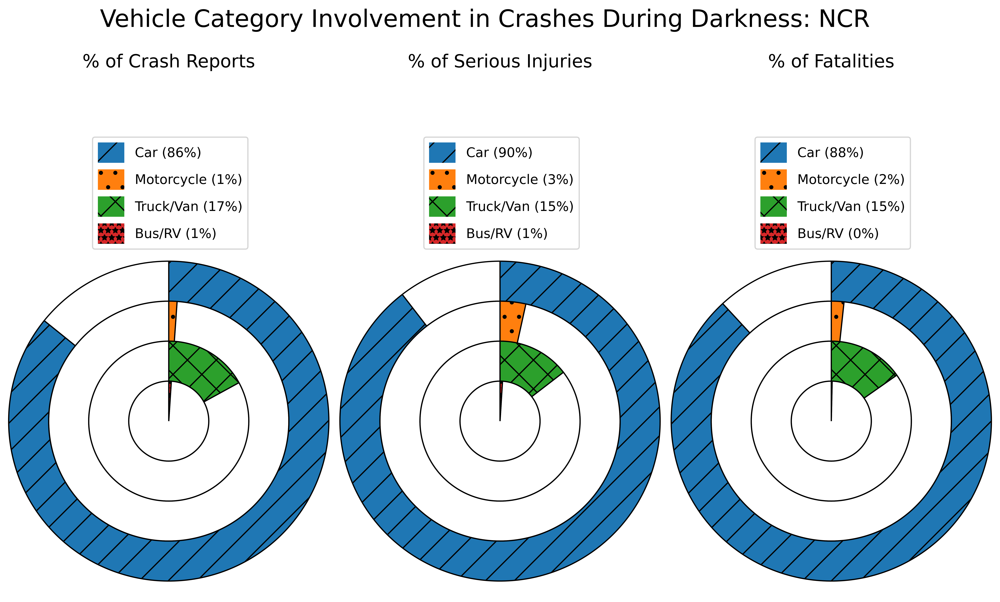

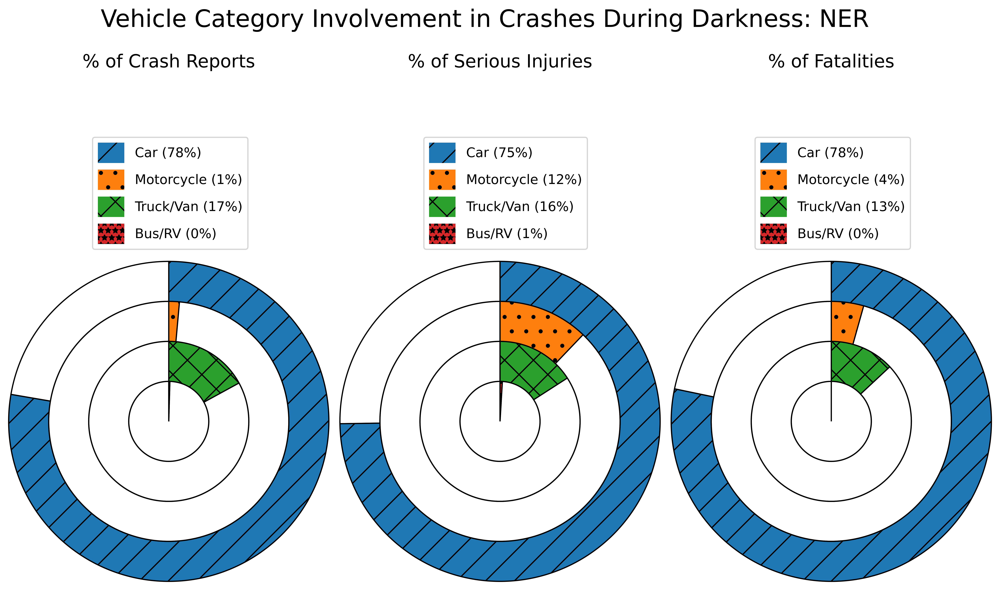

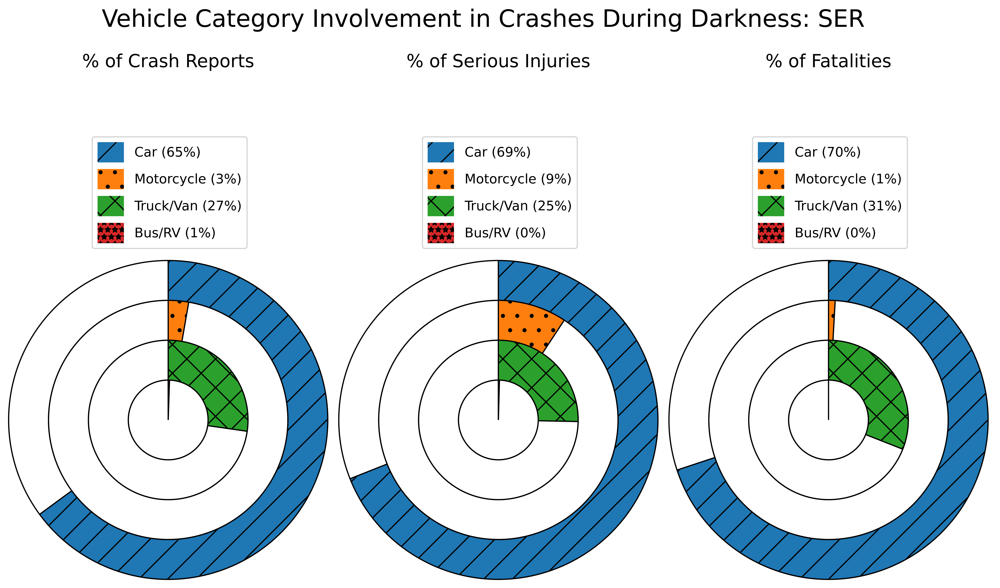

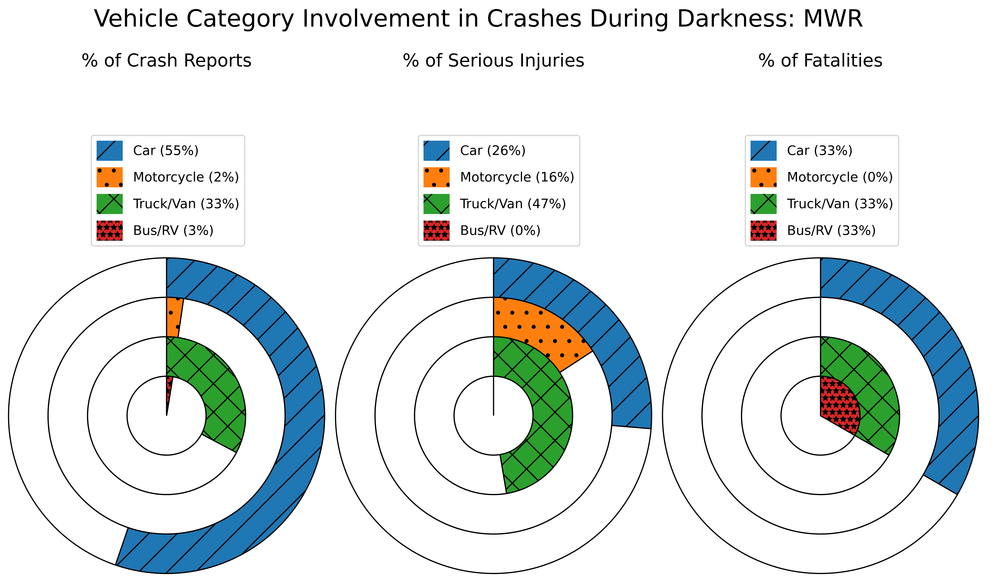

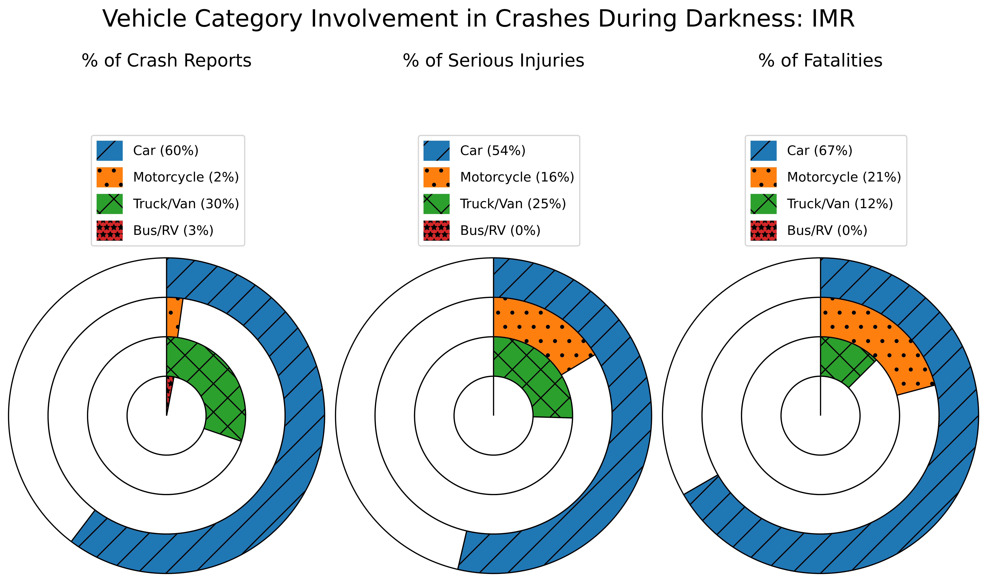

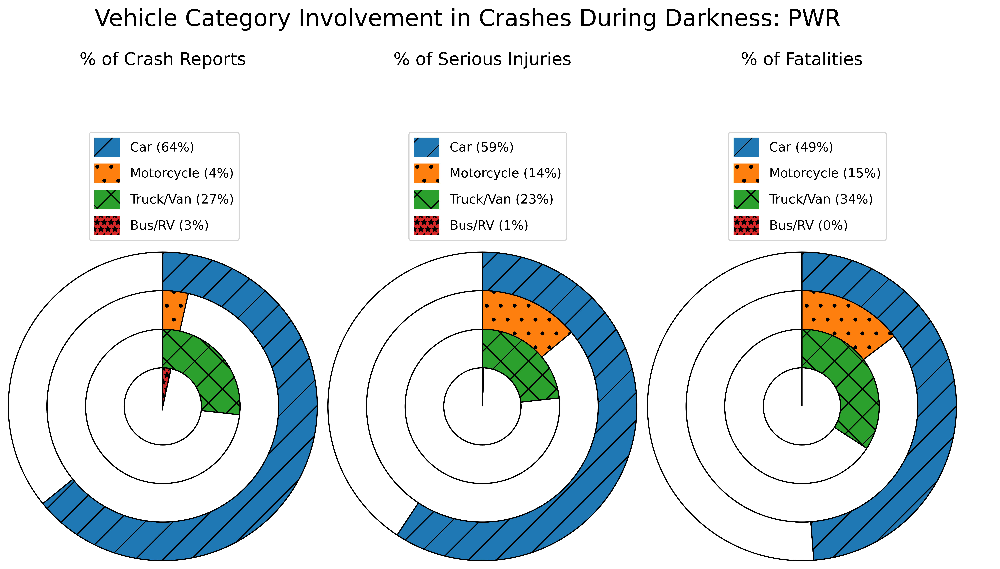

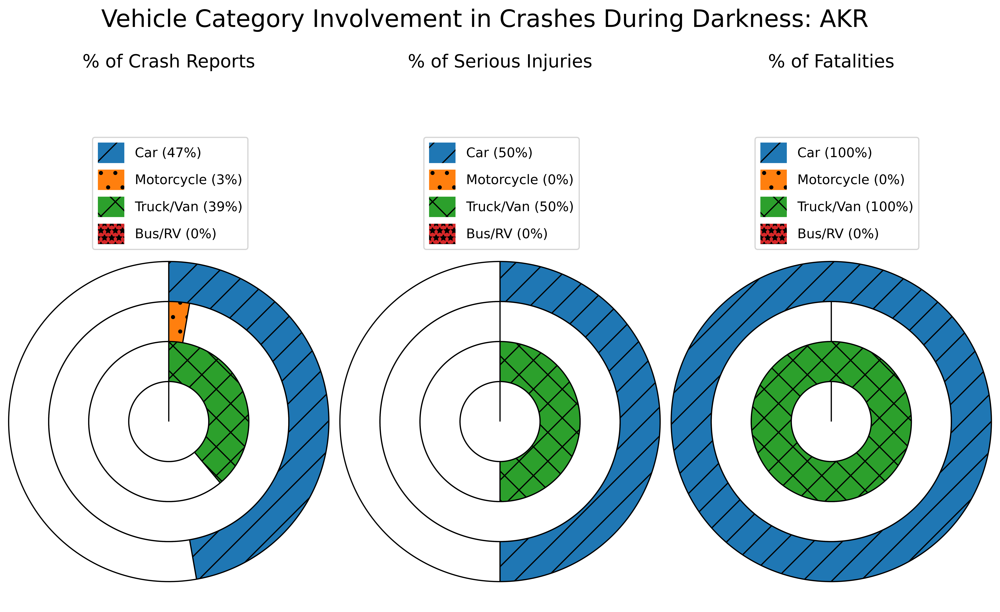

In [33]:
# modified example in following URL: https://stackoverflow.com/questions/49729748/create-a-circular-barplot-in-python

from matplotlib import cm

# combine all vehicle types into general categories
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
analysis_2024['Car'] = analysis_2024['Pax'] + analysis_2024['SUV']
analysis_2024['Truck'] = analysis_2024['Van'] + analysis_2024['Medium Truck'] + analysis_2024['Heavy Truck']
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]

vehicle_columns = ['Car', 'Num_Motorcycle', 'Truck', 'Bus'] # to determine bar values in loop through each vehicle type data column

n = len(vehicle_columns) # number of rings
r = 1.45 # radius of whole pie
w = r / n  # width of each ring
m = 100 # max possible ring value, to represent percents with the typical visual convention (e.g., 75% = 3/4 of the pie)

labels = ['Car', 'Motorcycle', 'Truck/Van', 'Bus/RV']
colors = ['tab:blue','tab:orange','tab:green','tab:red']
patterns=['/','.','x','**']
textprops = {"alpha": 0} # hide labels in segments (alpha of 0 = transparent)

# establish patch color and hatching to accompany legend category and percent value label, which seems to throw off automatic patch formatting
car_patch = mpatches.Patch(hatch=patterns[0], facecolor=colors[0])
motorcycle_patch = mpatches.Patch(hatch=patterns[1], facecolor=colors[1])
truck_patch = mpatches.Patch(hatch=patterns[2], facecolor=colors[2])
bus_patch = mpatches.Patch(hatch=patterns[3], facecolor=colors[3])

for region in regions:
    df = dark.loc[dark['RGN']==region]
    dark_fatalities = []
    dark_serious_injuries = []
    dark_crashes = []

    for i in vehicle_columns:
        # np.nan_to_num() is numpy equivalent of pandas .fillna(0) to avoid divide by zero errors in percentage calcs
        # note that boolean syntax references all rows where the vehicle type is greater than zero because the analysis database indicates a count of each vehicle type involved in each crash rather than a Y/N binary flag for vehicle type involvement
        perc_dark_fatalities = np.nan_to_num(df.loc[df[i]>0]['Fatality'].sum()/df['Fatality'].sum()*100) # percent of total region dark fatalities
        dark_fatalities.append(perc_dark_fatalities)
        perc_dark_serious_injuries = np.nan_to_num(df.loc[df[i]>0]['Incapacitating Injury'].sum()/df['Incapacitating Injury'].sum()*100) # percent of total region dark serious injuries 
        dark_serious_injuries.append(perc_dark_serious_injuries)    
        perc_dark_crashes = np.nan_to_num(df.loc[df[i]>0].shape[0]/df.shape[0]*100) # integer-rounded percent of total region dark crashes
        dark_crashes.append(perc_dark_crashes)

    # create 1 row of 3 plots
    fig, ax = plt.subplots(1,3, figsize=(14,10), dpi=700)
    fig.suptitle('Vehicle Category Involvement in Crashes During Darkness: ' + region, fontsize=20)

    #create rings of donut chart
    for i in range(n):
        innerring, _ = ax[2].pie([(m-dark_fatalities[i]), dark_fatalities[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
        plt.setp(innerring, width = w, edgecolor = "k")
        innerring, _ = ax[1].pie([(m-dark_serious_injuries[i]), dark_serious_injuries[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
        plt.setp(innerring, width = w, edgecolor = "k")
        innerring, _ = ax[0].pie([(m-dark_crashes[i]), dark_crashes[i]], radius=r-i*w, startangle=90, labels=["",labels[i]], textprops=textprops, colors=["none",colors[i]], hatch=["",patterns[i]]) # note that first color and hatch pattern define the "whitespace" fill color and hatching 
        plt.setp(innerring, width = w, edgecolor = "k")

    ax[2].set_title("% of Fatalities", fontsize=15, pad=180)
    ax[2].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_fatalities)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly
    ax[1].set_title("% of Serious Injuries", fontsize=15, pad=180)
    ax[1].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_serious_injuries)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly
    ax[0].set_title("% of Crash Reports", fontsize=15, pad=180)
    ax[0].legend(labels=[f'{l} ({d:.0f}%)' for l, d in zip(labels, dark_crashes)], handles = [car_patch, motorcycle_patch, truck_patch, bus_patch], fontsize=11, bbox_to_anchor=(0.2, 1.1), handleheight=2) # label = "<vehicle type category> (int(percent value)%)"; move legend outside of plot and increase patch size to view hatch pattern clearly
    
    #fig_name = './Figures/Radial Bar Charts/Vehicle Categories/' + region + " Horizontal Annotated Percentages.png"
    #plt.savefig(fig_name)

## Crash Reports by Year

<ipython-input-4-8552befdeec0>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Num_Crash'] = 1
<ipython-input-4-8552befdeec0>:14: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-4-8552befdeec0>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-c

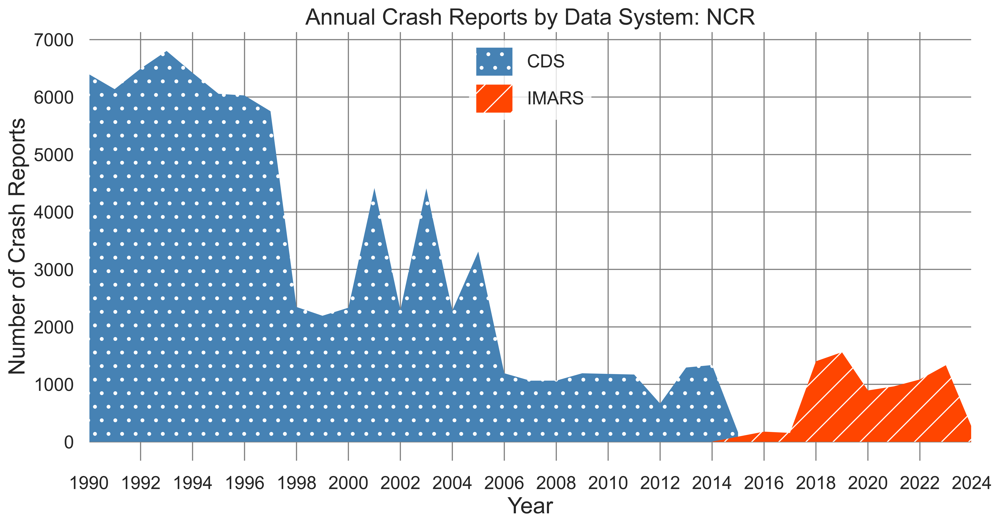

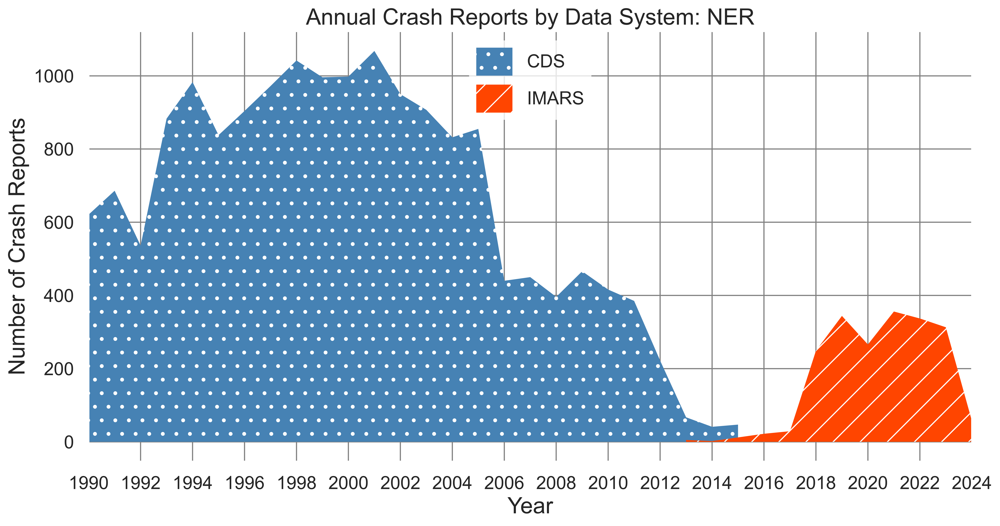

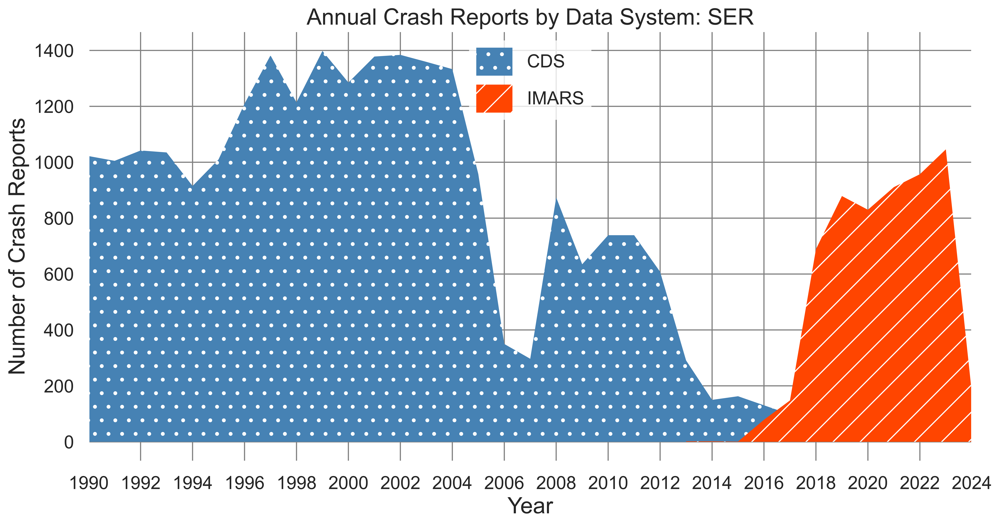

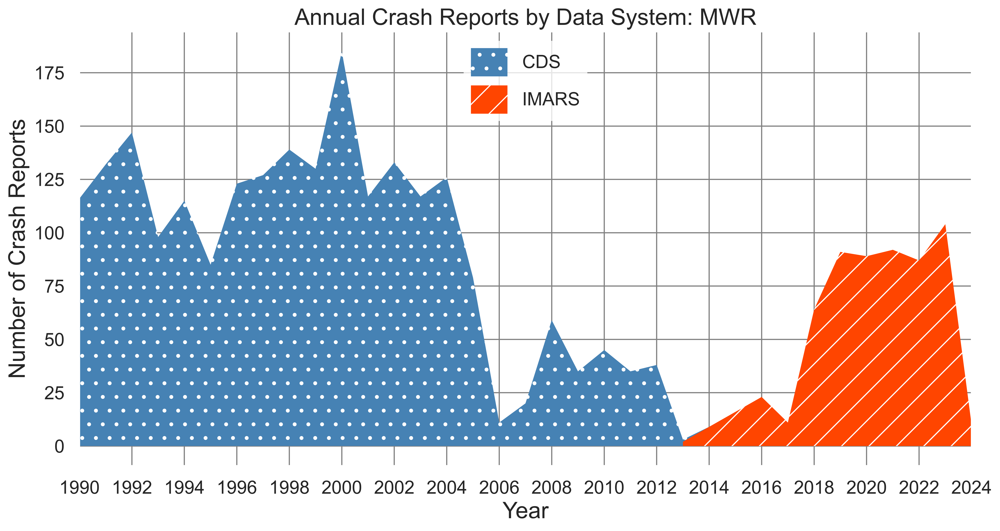

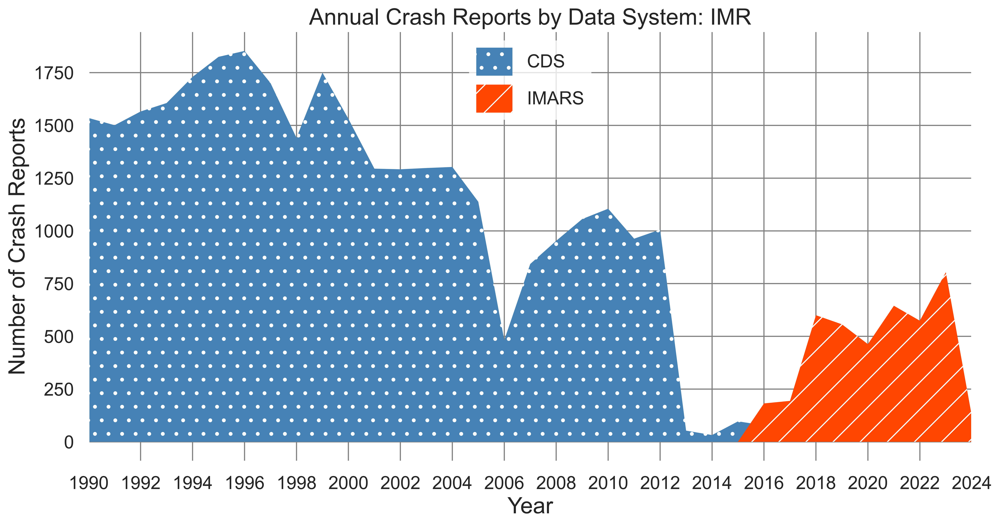

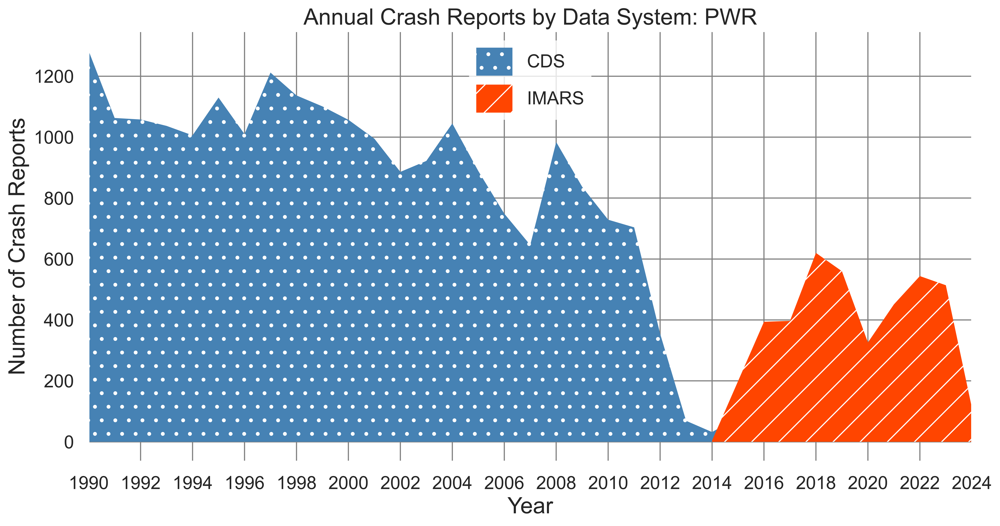

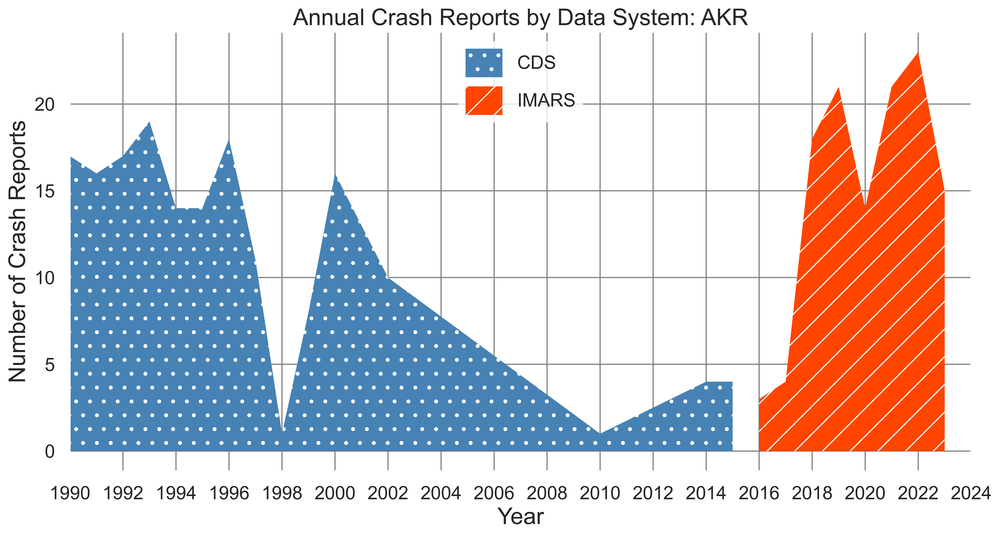

In [4]:
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    
    # set up dataframes for plotting
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    df['Num_Crash'] = 1
    goodyears = df.loc[df['YEAR'].isin(range(1988,2025))]
    imars_all_year = goodyears.loc[goodyears['database']=="IMARS"].groupby('YEAR')
    cds_all_year = goodyears.loc[goodyears['database']=="CDS"].groupby('YEAR')
    imars_all_year_crashcounts = imars_all_year['Num_Crash'].sum()
    cds_all_year_crashcounts = cds_all_year['Num_Crash'].sum()
    
    # set up figure
    plt.style.use('seaborn')
    tick_spacing = 2 
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'none', 'patch.linewidth': 0.0})
    fig,ax = plt.subplots(1,1, figsize=(14, 7), dpi=700)
    
    # plot data
    ax.fill_between(cds_all_year_crashcounts.index, cds_all_year_crashcounts, label = 'CDS', facecolor = "steelblue", hatch = '.')
    ax.fill_between(imars_all_year_crashcounts.index, imars_all_year_crashcounts, label = 'IMARS', facecolor = "orangered", hatch = '/')
    
    # format plot
    ax.set_title('Annual Crash Reports by Data System: ' + region, fontsize=20)
    legend = plt.legend(fontsize=16, handleheight=2, frameon=True, edgecolor='black', loc=9)
    plt.xlim([1990,2024])
    ax.grid(visible=True, color = 'gray')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax.tick_params(which='major', labelsize=16)
    ax.set_xlabel("Year", fontsize=20)
    ax.set_ylabel("Number of Crash Reports", fontsize=20)
    
    fig_name = './Figures/Volume Plots/Crash Reports by Year/' + region + ".png"
    plt.savefig(fig_name)

# Prep Data Tables

In [40]:
analysis_2024["Urban"].value_counts() # how to handle "suburban"?

Urban
urban       90270
rural       67020
suburban    43810
Name: count, dtype: int64

In [41]:
pd.options.display.max_rows = 10000000
suburb = analysis_2024.loc[analysis_2024["Urban"]=="suburban"]
suburb["Park"].value_counts() # from top 10 parks, it looks like I can comfortably reclassify "suburban" as "rural" for the sake of lighting likelihood

Park
GRSM    8600
NATR    8507
BLRI    8257
DEWA    5785
SHEN    1963
COLO    1851
SAGU    1406
CUGA    1158
GETT    1127
CHCH     823
EVER     561
INDU     512
CHOH     407
HOSP     357
GUIS     309
FRSP     302
CUVA     290
PRWI     243
CATO     141
ANTI     133
MANA     110
HAFE      91
CANA      73
BITH      57
STEA      47
RICH      45
GUCO      44
PETR      39
PETE      38
FIIS      34
LIRI      31
MUWO      27
JELA      27
HOFR      26
FONE      21
ALPO      21
EISE      20
KIMO      19
TICA      18
NERI      16
JOFL      15
CORO      15
SARA      14
HEHO      14
SAAN      13
BOWA      12
VIIS      10
WICR      10
CONG      10
STRI      10
BISC      10
KLGO      10
OCMU      10
VALR       9
FOPU       8
GRFA       8
KAHO       8
MONO       7
HOFU       7
CAGR       6
FOMA       6
CHIS       6
FRHI       6
CARL       5
VAMA       5
ANJO       5
FRST       4
CUIS       4
GERO       3
WHMI       3
GLEC       3
PERI       3
FOSU       2
ELRO       2
FOFR       2
PERL       1
TUSK   

In [42]:
analysis_2024['Urban'] = np.where(analysis_2024['Urban']=="suburban", "rural",analysis_2024['Urban'])
analysis_2024['Urban'].value_counts()

Urban
rural    110830
urban     90270
Name: count, dtype: int64

In [43]:
# focus on darkness attributes re: poor visibility
analysis_2024['Urban'] = np.where(analysis_2024['Urban']=="suburban", "rural",analysis_2024['Urban']) # in case above cell is not run first
dark = analysis_2024.loc[analysis_2024["Poor Lighting"]==1]

# add outcome columns to set up analysis data tables
dark['Num_Crash'] = 1
dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
length = range(dark.shape[0])
for i in length: # in order of most to least common to speed up processing
    if dark['Dark_NotLit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Not Lit"
    elif dark['Dark_Lit'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dark - Lit"
    elif dark['Dusk'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dusk"
    elif dark['Dawn'].iloc[i]==1:
        dark['Darkness Attribute'].iloc[i] = "Dawn"
    else:
        dark['Darkness Attribute'].iloc[i] = 'Dark - Unknown Lighting'

<ipython-input-43-b2e80d8d1710>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Num_Crash'] = 1
<ipython-input-43-b2e80d8d1710>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark['Darkness Attribute'] = 0 # initialize column with dummy data to replace with for loop
<ipython-input-43-b2e80d8d1710>:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#

## First Harmful Event Type Table - Rates

In [44]:
#doc_name = './Tables/First Harmful Event Type.docx' # append existing document
#doc = docx.Document(doc_name)
#doc.add_paragraph(" ")
#doc.add_paragraph("Regional Outcome Rates from Crashes During Darkness by First Harmful Event Type", style="Title") # if needed, troubleshoot using this link: https://stackoverflow.com/questions/54945258/python-docx-unable-to-use-existing-document-no-style-with-name-title
#doc.add_paragraph(" ")
#doc.add_paragraph("MANUALLY AUTOFIT EACH TABLE TO CONTENTS")
#doc.add_paragraph(" ")
regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    df = dark.loc[dark['RGN']==region]
    
    dark_eventtype_outcomes = df[['Num_Crash','Incapacitating Injury','Fatality','First_Harmful_Event_Type']] # subset for metrics Wayne is looking for
    # outcomes for each first harmful event type, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
    dark_eventtype_agg = dark_eventtype_outcomes.groupby(['First_Harmful_Event_Type']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
    dark_eventtype_rates = dark_eventtype_agg[["First_Harmful_Event_Type", "Num_Crash"]]
    dark_eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
    dark_eventtype_rates['Average Serious Injury "Rate"'] = np.nan_to_num(round(dark_eventtype_agg['Num_Crash']/dark_eventtype_agg['Incapacitating Injury'],0)).astype(int) # compute number of crashes per serious injury
    dark_eventtype_rates['Average Serious Injury "Rate"'] = dark_eventtype_rates['Average Serious Injury "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
    dark_eventtype_rates['Average Serious Injury "Rate"'] = "1 every " + dark_eventtype_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
    dark_eventtype_rates['Average Fatality "Rate"'] = np.nan_to_num(round(dark_eventtype_agg['Num_Crash']/dark_eventtype_agg['Fatality'],0)).astype(int) # compute number of crashes per fatality
    dark_eventtype_rates['Average Fatality "Rate"'] = dark_eventtype_rates['Average Fatality "Rate"'].astype(str) # convert to string to prepare for text prepend and append in table cell value
    dark_eventtype_rates['Average Fatality "Rate"'] = "1 every " + dark_eventtype_rates['Average Fatality "Rate"'] + " crashes" # "1 fatality for every X crashes"
    
    # when 0 serious injuries or fatalities, rate does not properly compute; replace with zero
    length = range(dark_eventtype_rates['Average Fatality "Rate"'].shape[0])
    for i in length:
        if dark_eventtype_rates['Average Fatality "Rate"'].iloc[i] == "1 every -2147483648 crashes":
            dark_eventtype_rates['Average Fatality "Rate"'].iloc[i] = 0
        if dark_eventtype_rates['Average Serious Injury "Rate"'].iloc[i] == "1 every -2147483648 crashes":
            dark_eventtype_rates['Average Serious Injury "Rate"'].iloc[i] = 0
    
    # format data table for display
    dark_eventtype_rates = dark_eventtype_rates.rename(columns={'First_Harmful_eventtype_Type':'First Harmful Event Type'})
    dark_eventtype_rates = dark_eventtype_rates.drop(columns={'Num_Crash'})

    #doc.add_paragraph("Outcome Rates from Crashes During Darkness: " + region, style="Heading 1")
    #t = doc.add_table(dark_eventtype_rates.shape[0]+1, dark_eventtype_rates.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    #for j in range(dark_eventtype_rates.shape[-1]):
    #    t.cell(0,j).text = dark_eventtype_rates.columns[j]

    #for i in range(dark_eventtype_rates.shape[0]):
    #    for j in range(dark_eventtype_rates.shape[-1]):
    #        t.cell(i+1,j).text = str(dark_eventtype_rates.values[i,j])

    #doc.save(doc_name)

<ipython-input-44-442f6d77c869>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype_outcomes.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
<ipython-input-44-442f6d77c869>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_eventtype_rates['Crash "Rate" (percent of total crashes)'] = round(dark_eventtype_agg['Num_Crash']/dark_eventtype

## Poor Lighting Attribute Outcomes - Rates

In [45]:
#doc_name = './Tables/Darkness Attribute.docx' # append existing document
#doc = docx.Document(doc_name)
#doc.add_paragraph(" ")
#doc.add_paragraph("Regional Outcome Rates from Crashes During Darkness by Darkness Attribute", style="Title") # if needed, troubleshoot using this link: https://stackoverflow.com/questions/54945258/python-docx-unable-to-use-existing-document-no-style-with-name-title
#doc.add_paragraph(" ")
#doc.add_paragraph("MANUALLY AUTOFIT EACH TABLE TO CONTENTS")
#doc.add_paragraph(" ")

regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    df = dark.loc[dark['RGN']==region]
    
    dark_summary = df[['Num_Crash','Incapacitating Injury','Fatality','Darkness Attribute']]
    # outcomes for each darkness attribute, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
    dark_summary_agg = dark_summary.groupby(['Darkness Attribute']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
    dark_summary_rates = dark_summary_agg[["Darkness Attribute", "Num_Crash"]]
    dark_summary_rates['Crash "Rate" (percent of total crashes)'] = round(dark_summary_agg['Num_Crash']/dark_summary.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
    dark_summary_rates['Average Serious Injury "Rate"'] = np.nan_to_num(round(dark_summary_agg['Num_Crash']/dark_summary_agg['Incapacitating Injury'],0)).astype(int) # compute number of crashes per serious injury
    dark_summary_rates['Average Serious Injury "Rate"'] = dark_summary_rates['Average Serious Injury "Rate"'].astype(str) # convert value to string for text prepend and append in table cell
    dark_summary_rates['Average Serious Injury "Rate"'] = "1 every " + dark_summary_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
    dark_summary_rates['Average Fatality "Rate"'] = np.nan_to_num(round(dark_summary_agg['Num_Crash']/dark_summary_agg['Fatality'],0)).astype(int) # compute number of crashes per fatality
    dark_summary_rates['Average Fatality "Rate"'] = dark_summary_rates['Average Fatality "Rate"'].astype(str) # convert value to string for text prepend and append in table cell
    dark_summary_rates['Average Fatality "Rate"'] = "1 every " + dark_summary_rates['Average Fatality "Rate"'] + " crashes"  # "1 fatality for every X crashes"
    
    # when 0 serious injuries or fatalities, rate does not properly compute; replace with zero
    length = range(dark_summary_rates['Average Fatality "Rate"'].shape[0])
    for i in length:
        if dark_summary_rates['Average Fatality "Rate"'].iloc[i] == "1 every -2147483648 crashes":
            dark_summary_rates['Average Fatality "Rate"'].iloc[i] = 0
        if dark_summary_rates['Average Serious Injury "Rate"'].iloc[i] == "1 every -2147483648 crashes":
            dark_summary_rates['Average Serious Injury "Rate"'].iloc[i] = 0
    
    # format data table for display
    dark_summary_rates = dark_summary_rates.drop(columns={'Num_Crash'})

    #doc.add_paragraph("Outcome Rates from Crashes During Darkness: " + region, style="Heading 1")
    #t = doc.add_table(dark_summary_rates.shape[0]+1, dark_summary_rates.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    #for j in range(dark_summary_rates.shape[-1]):
    #    t.cell(0,j).text = dark_summary_rates.columns[j]

    #for i in range(dark_summary_rates.shape[0]):
    #    for j in range(dark_summary_rates.shape[-1]):
    #        t.cell(i+1,j).text = str(dark_summary_rates.values[i,j])
    
    #doc.save(doc_name)

<ipython-input-45-4bc2d0146ad6>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_summary_rates['Crash "Rate" (percent of total crashes)'] = round(dark_summary_agg['Num_Crash']/dark_summary.shape[0]*100,1).astype(str) + "%" # convert percent value to string in order to append percent symbol
<ipython-input-45-4bc2d0146ad6>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_summary_rates['Crash "Rate" (percent of total crashes)'] = round(dark_summary_agg['Num_Crash']/dark_summary.shape[0]*100,1).asty

## General Lighting Categories - Rates

In [46]:
analysis_2024['Num_Crash'] = 1
analysis_2024['Lighting Category'] = 0 # initialize column with dummy data to replace with for loop

# assign general lighting categories
length = range(analysis_2024.shape[0])
for i in length: # in order of most to least common to speed up processing
    if analysis_2024['Daylight'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Daylight"
    elif analysis_2024['UnknownBlankNullLit'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Unknown"
    elif analysis_2024['Poor Lighting'].iloc[i]==1:
        analysis_2024['Lighting Category'].iloc[i] = "Dark"

analysis_2024['Lighting Category'].value_counts() # 87 counts of "0" from IMARS crashes in which lighting was described as "other" and could therefore not fit into the other three broad categories

<ipython-input-46-556eed5ee02c>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  analysis_2024['Lighting Category'].iloc[i] = "Daylight"


Lighting Category
Daylight    108608
Unknown      68731
Dark         41167
0               87
Name: count, dtype: int64

In [47]:
#doc_name = './Tables/Lighting Category.docx' # append existing document
#doc = docx.Document(doc_name)
#doc.add_paragraph(" ")
#doc.add_paragraph("Regional Outcome Rates by General Lighting Category", style="Title") # if needed, troubleshoot using this link: https://stackoverflow.com/questions/54945258/python-docx-unable-to-use-existing-document-no-style-with-name-title
#doc.add_paragraph(" ")
#doc.add_paragraph("MANUALLY AUTOFIT EACH TABLE TO CONTENTS")
#doc.add_paragraph(" ")

regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:
    df_clean = analysis_2024.loc[analysis_2024['Lighting Category']!=0] # remove 45 "other" lighting crashes from IMARS
    df = df_clean.loc[df_clean['RGN']==region]
    
    df_summary = df[['Num_Crash','Incapacitating Injury','Fatality','Lighting Category']]
    # outcomes for each lighting category, ordered by most to least common in crash report (reset index such that groupby data are now column in dataframe and can be manipulated as such)
    df_summary_agg = df_summary.groupby(['Lighting Category']).sum().sort_values(by=['Num_Crash'],ascending=False).reset_index()
    
    df_summary_rates = df_summary_agg[["Lighting Category", "Num_Crash"]]
    df_summary_rates['Crash "Rate" (percent of total crashes)'] = round(df_summary_agg['Num_Crash']/df_summary.shape[0]*100,1).astype(str) + "%" # convert rounded percent value to string in order to append percent symbol
    df_summary_rates['Average Serious Injury "Rate"'] = np.nan_to_num(round(df_summary_agg['Num_Crash']/df_summary_agg['Incapacitating Injury'],0)).astype(int) # compute number of crashes per serious injury
    df_summary_rates['Average Serious Injury "Rate"'] = df_summary_rates['Average Serious Injury "Rate"'].astype(str) # convert to string required for text prepend and append
    df_summary_rates['Average Serious Injury "Rate"'] = "1 every " + df_summary_rates['Average Serious Injury "Rate"'] + " crashes" # "1 serious injury for every X crashes"
    df_summary_rates['Average Fatality "Rate"'] = np.nan_to_num(round(df_summary_agg['Num_Crash']/df_summary_agg['Fatality'],0)).astype(int) # compute number of crashes per fatality
    df_summary_rates['Average Fatality "Rate"'] = df_summary_rates['Average Fatality "Rate"'].astype(str) # convert to string required for text prepend and append
    df_summary_rates['Average Fatality "Rate"'] = "1 every " + df_summary_rates['Average Fatality "Rate"'] + " crashes" # "1 fatality for every X crashes"
    
    # format data table for display
    df_summary_rates = df_summary_rates.drop(columns={'Num_Crash'})

    #doc.add_paragraph("Outcome Rates by Lighting Category: " + region, style="Heading 1")
    #t = doc.add_table(df_summary_rates.shape[0]+1, df_summary_rates.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    #for j in range(df_summary_rates.shape[-1]):
    #    t.cell(0,j).text = df_summary_rates.columns[j]

    #for i in range(df_summary_rates.shape[0]):
    #    for j in range(df_summary_rates.shape[-1]):
    #        t.cell(i+1,j).text = str(df_summary_rates.values[i,j])
    
    #doc.save(doc_name)

<ipython-input-47-6e11c359c181>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_summary_rates['Crash "Rate" (percent of total crashes)'] = round(df_summary_agg['Num_Crash']/df_summary.shape[0]*100,1).astype(str) + "%" # convert rounded percent value to string in order to append percent symbol
<ipython-input-47-6e11c359c181>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_summary_rates['Crash "Rate" (percent of total crashes)'] = round(df_summary_agg['Num_Crash']/df_summary.shape[0]*100,1).astype(s

## Urban/Rural

In [58]:
# run in case servicewide urban/rural was not generated first (not all prior cells run)
dark_slim = dark.loc[dark["Darkness Attribute"].isin(["Dark - Lit", "Dark - Not Lit"])]
dark_slim["urb"] = np.where(dark_slim['Urban']=="urban",1,0)
dark_slim["rur"] = np.where(dark_slim["Urban"]=="rural",1,0)
darklit = dark_slim.loc[dark_slim["Darkness Attribute"]=="Dark - Lit"]
darkunlit = dark_slim.loc[dark_slim["Darkness Attribute"]=="Dark - Not Lit"]

from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches  

regions = ["NCR", "NER", "SER", "MWR", "IMR", "PWR", "AKR"]
for region in regions:

    # data prep
    darklit_rgn = darklit.loc[darklit["RGN"]==region]
    darkunlit_rgn = darkunlit.loc[darkunlit["RGN"]==region]
    UrbanLitPerc = [round(darklit_rgn['urb'].sum()/darklit_rgn.shape[0]*100,0), round(darkunlit_rgn['urb'].sum()/darkunlit_rgn.shape[0]*100,0)]
    RuralLitPerc = [round(darklit_rgn['rur'].sum()/darklit_rgn.shape[0]*100,0), round(darkunlit_rgn['rur'].sum()/darkunlit_rgn.shape[0]*100,0)]
    # some percentage calcs may have divide by zero errors if there are no crashes with lit or not lit lighting conditions
    # reformat nan to 0 for proper labeling in bar total annotations
    UrbanLitPerc = np.nan_to_num(UrbanLitPerc) 
    RuralLitPerc = np.nan_to_num(RuralLitPerc)
    
#    # plot prep
#    plt.style.use('seaborn')
#    fig, ax = plt.subplots(figsize=(14,7), dpi=700)
#    fig.suptitle('Urban/Rural Proportion of Crashes During Darkness with Known Lighting Conditions: ' + region, fontsize=24)

#    # data
#    x1 = [0, 1.25]
#    x2 = [0.5, 1.75]
#    ax.bar(x1, UrbanLitPerc, width = 0.5, hatch = "|", color = 'tab:blue', edgecolor = "black", linewidth=2, label='Urban')
#    ax.bar(x2, RuralLitPerc, width = 0.5, hatch = "-", color = 'tab:orange', edgecolor = "black", linewidth=2, label='Rural')

#    # annotate plot with bar totals
#    rects = ax.patches
#    labels = [f"label{i}" for i in range(len(rects))]
#    for rect, label in zip(rects, labels):
#        height = rect.get_height()
#        label = '{:,}'.format(int(height))
#        ax.text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

#    # format plot    
#    ax.set_ylim([0, 100])
#    ax.hlines(0, xmin = -0.25, xmax = 2, linewidth = 3)
#    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
#    ax.set_xlabel('Lighting Condition',fontsize = 18)
#    ax.set_ylabel("% of Crash Reports", fontsize = 18)
#    ax.tick_params(axis='x', which='major', labelsize=20)
#    ax.set_xticks([0.25, 1.5])
#    ax.set_xticklabels(['Lit','Not Lit'])
#    ax.tick_params(axis='y', which='major', labelsize=16)
#    ax.tick_params(axis='both', which='minor', labelsize=8)
#    ax.legend(fontsize='x-large', handleheight=3, handlelength = 2, bbox_to_anchor=(1.1, 1))
#    ax.set_facecolor('none')

#    fig_name = './Figures/Bar Charts/Urban Rural/' + region + ' Lit Unlit Proportions.png'
#    plt.savefig(fig_name)

<ipython-input-58-21da93cf5038>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_slim["urb"] = np.where(dark_slim['Urban']=="urban",1,0)
<ipython-input-58-21da93cf5038>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dark_slim["rur"] = np.where(dark_slim["Urban"]=="rural",1,0)
<ipython-input-58-21da93cf5038>:17: RuntimeWarning: invalid value encountered in longlong_scalars
  UrbanLitPerc = [round(darklit_rgn['urb'].sum()/darklit_rgn.shape[0]*100,0), round(darkunlit_rgn['urb'].sum()/darkunlit_rgn.shape